# explorative data analysis

first look into the fetched air quality data of the 4 selected stations in cologne

## libraries

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

## import fetched data

In [6]:
df = pd.read_parquet("../data/processed/cologne_measures_2016_2024.parquet")
print(df)

       station          date_start  component  scope  value  \
0         1108 2016-01-01 00:00:00          1      2    NaN   
1         1108 2016-01-01 01:00:00          1      2    NaN   
2         1108 2016-01-01 02:00:00          1      2  234.0   
3         1108 2016-01-01 03:00:00          1      2   98.0   
4         1108 2016-01-01 04:00:00          1      2   61.0   
...        ...                 ...        ...    ...    ...   
631291    1255 2024-12-31 19:00:00          5      2   14.0   
631292    1255 2024-12-31 20:00:00          5      2   13.0   
631293    1255 2024-12-31 21:00:00          5      2   17.0   
631294    1255 2024-12-31 22:00:00          5      2   23.0   
631295    1255 2024-12-31 23:00:00          5      2   24.0   

                  date_end index  
0      2016-01-01 01:00:00  None  
1      2016-01-01 02:00:00  None  
2      2016-01-01 03:00:00    10  
3      2016-01-01 04:00:00    10  
4      2016-01-01 05:00:00    10  
...                    ...   ... 

## descriptive analysis

### amount of missing values

In [7]:
df.isna().sum()

station           0
date_start        0
component         0
scope             0
value         22286
date_end          0
index         22287
dtype: int64

In [8]:
na_results = []
for station in df["station"].unique():
    for component in df["component"].unique():
        df_part = df[(df["station"] == station) & (df["component"] == component)]
        missing_vals = df_part["value"].isna().sum()
        missing_index = df_part["index"].isna().sum()
        na_results.append(
            {
                "station id": station,
                "component id": component,
                "missing values": missing_vals,
                "missing indexes": missing_index,
            }
        )

na_df = pd.DataFrame(na_results)
print(na_df)

  station id  component id  missing values  missing indexes
0       1108             1            2535             2536
1       1108             5            3637             3637
2       1114             1            1849             1849
3       1114             5            3634             3634
4       1254             1            1220             1220
5       1254             5            3423             3423
6       1255             1            1280             1280
7       1255             5            4708             4708


In [6]:
df.groupby(["station", "component"])["value"].apply(lambda s: s.isna().sum())

station  component
1108     1            2535
         5            3637
1114     1            1849
         5            3634
1254     1            1220
         5            3423
1255     1            1280
         5            4708
Name: value, dtype: int64

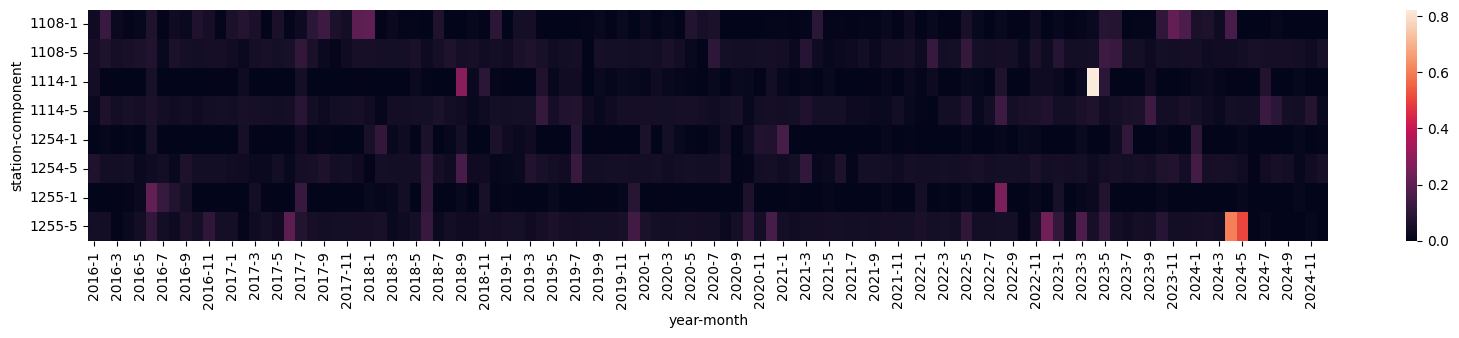

In [9]:
df["is_na"] = df["value"].isna()
df["year"] = df["date_start"].dt.year
df["month"] = df["date_start"].dt.month
df["weekday"] = df["date_start"].dt.weekday
df["hour"] = df["date_start"].dt.hour

matrix = df.pivot_table(
    values="is_na",
    index=["station", "component"],
    columns=["year", "month"],
    aggfunc="mean",
)

plt.figure(figsize=(20, 3))
sns.heatmap(matrix)
plt.show()

### trend analysis (lineplots)

for example for the year 2020

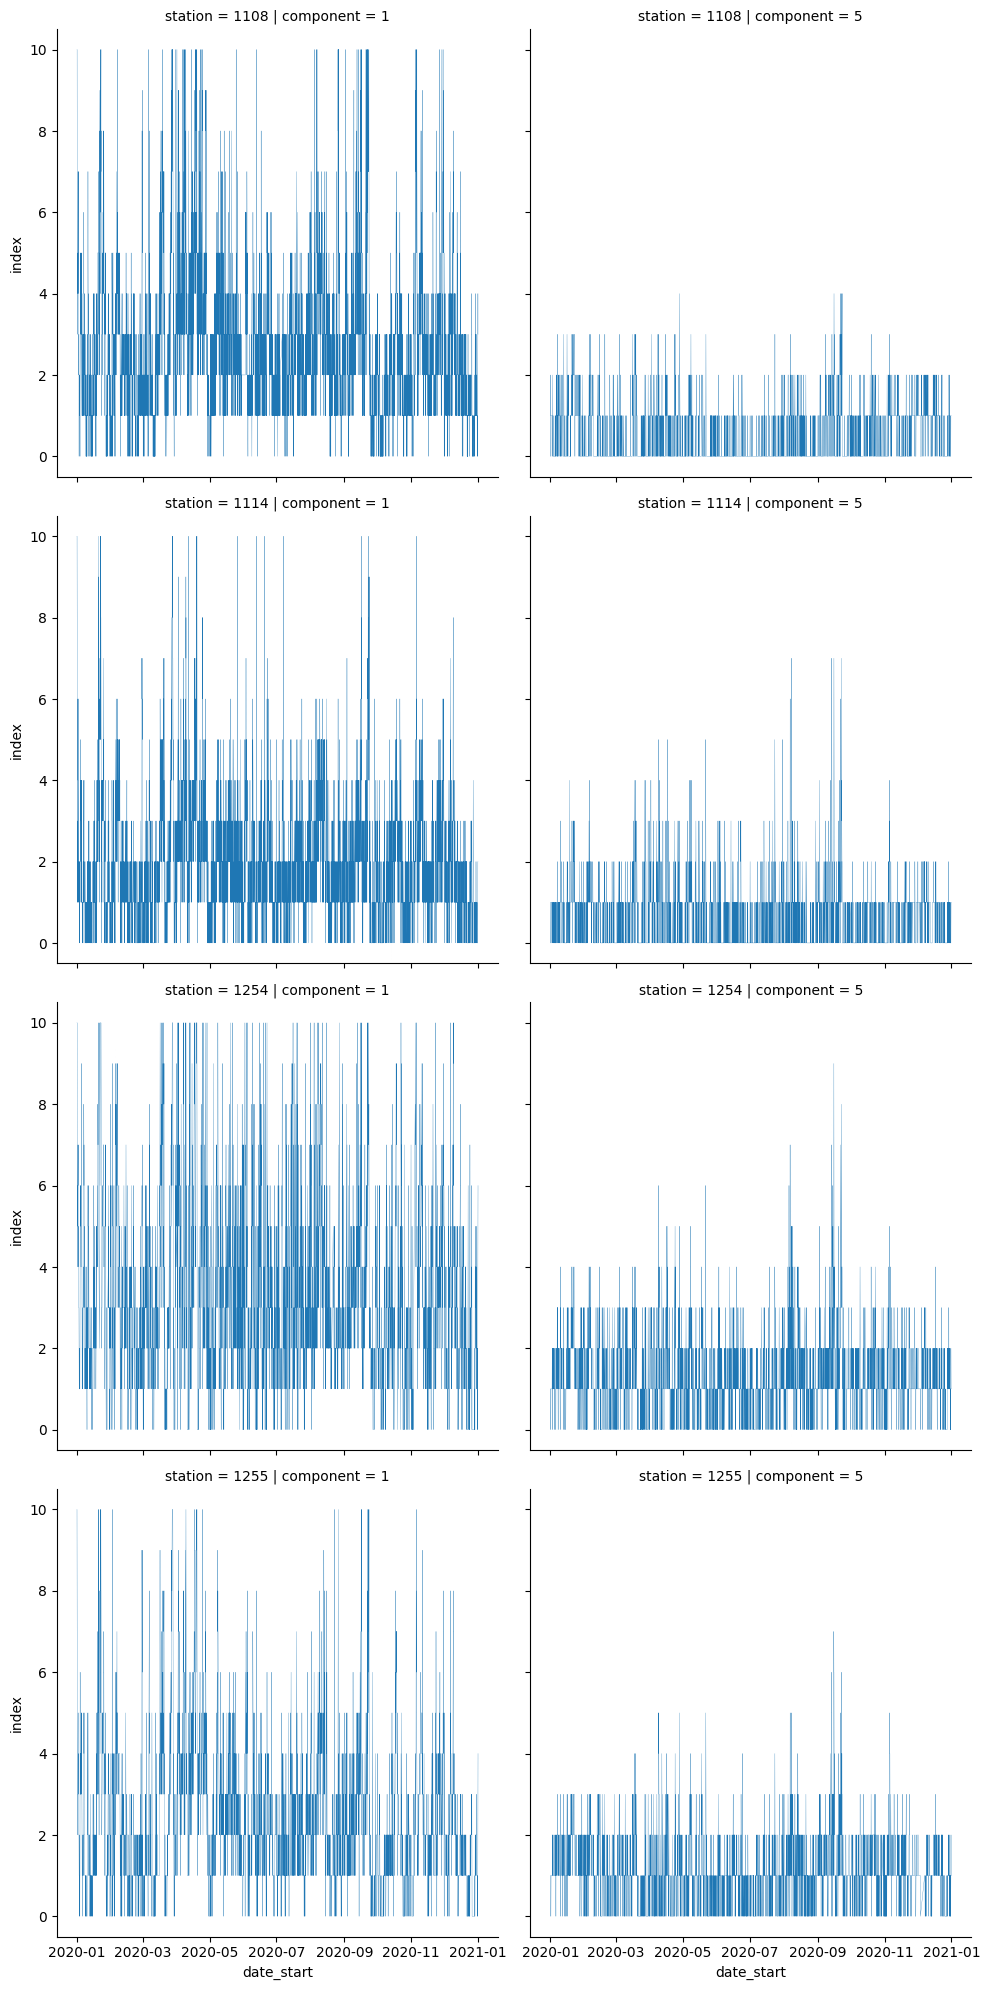

In [10]:
df["index"] = pd.to_numeric(df["index"])
sns.relplot(
    data=df[df["date_start"].dt.year == 2020],
    x="date_start",
    y="index",
    kind="line",
    row="station",
    col="component",
    linewidth=0.2,
)

### distribution analysis (kdes & histograms)

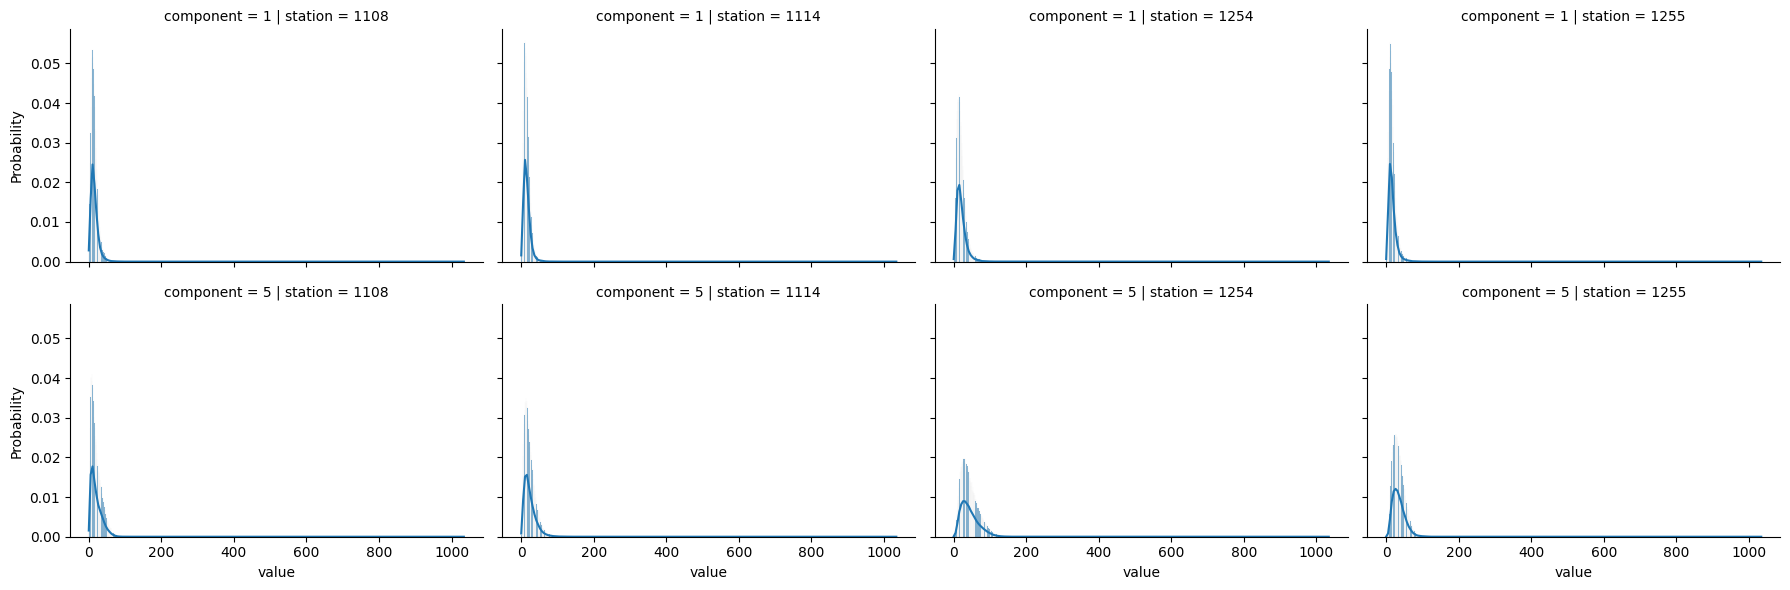

In [11]:
sns.displot(
    data=df,
    x="value",
    row="component",
    col="station",
    stat="probability",
    kde=True,
    height=3,
    aspect=1.5,
    common_norm=False,
)

> skewed to the right: log transformation makes sense \
> the traffic stations (1254, 1255) seem to be less skewed than the background stations (1108, 1114)

### outlier analysis (boxplots)

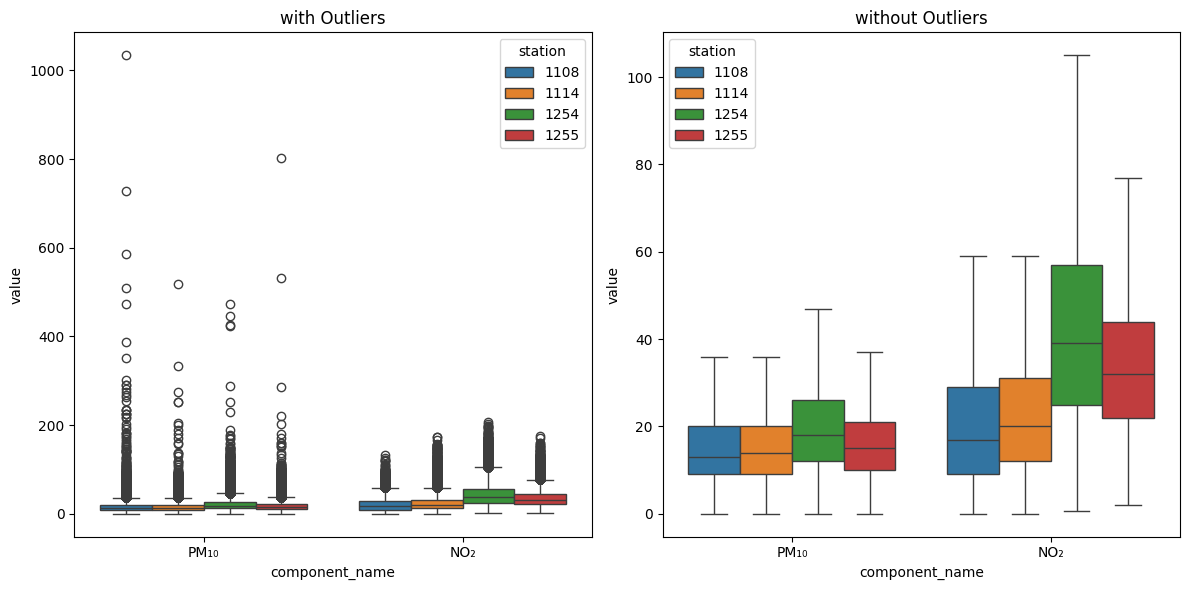

In [12]:
df["component_name"] = df["component"].map({1: "PM₁₀", 5: "NO₂"})

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=False)

sns.boxplot(data=df, x="component_name", y="value", hue="station", ax=axes[0])
sns.boxplot(
    data=df, x="component_name", y="value", hue="station", showfliers=False, ax=axes[1]
)

axes[0].set_title("with Outliers")
axes[1].set_title("without Outliers")
plt.tight_layout()
plt.show()

> background stations: 1108, 1114 (Chorweiler, Rodenkirchen) \
> traffic stations: 1254, 1255 (Clevischer Ring, Turiner Straße) \
> => slightly elevated emissions at traffic stations \
> PM₁₀ has more extreme outliers \
> => importance of robust modeling

### function for average-concentration plotting

In [13]:
def calc_curves(by, data=df):
    mean = data.groupby(["station", "component", by])["value"].mean().reset_index()
    median = data.groupby(["station", "component", by])["value"].median().reset_index()
    mean["stat"] = "mean"
    median["stat"] = "median"
    mea_med = pd.concat([mean, median], ignore_index=True)
    mea_med["component_name"] = mea_med["component"].map({1: "PM₁₀", 5: "NO₂"})
    mea_med["station_name"] = mea_med["station"].map(
        {
            "1108": "Chorweiler",
            "1114": "Rodenkirchen",
            "1254": "Clevischer Ring",
            "1255": "Turiner Straße",
        }
    )

    return mea_med

### average concetration per hour 

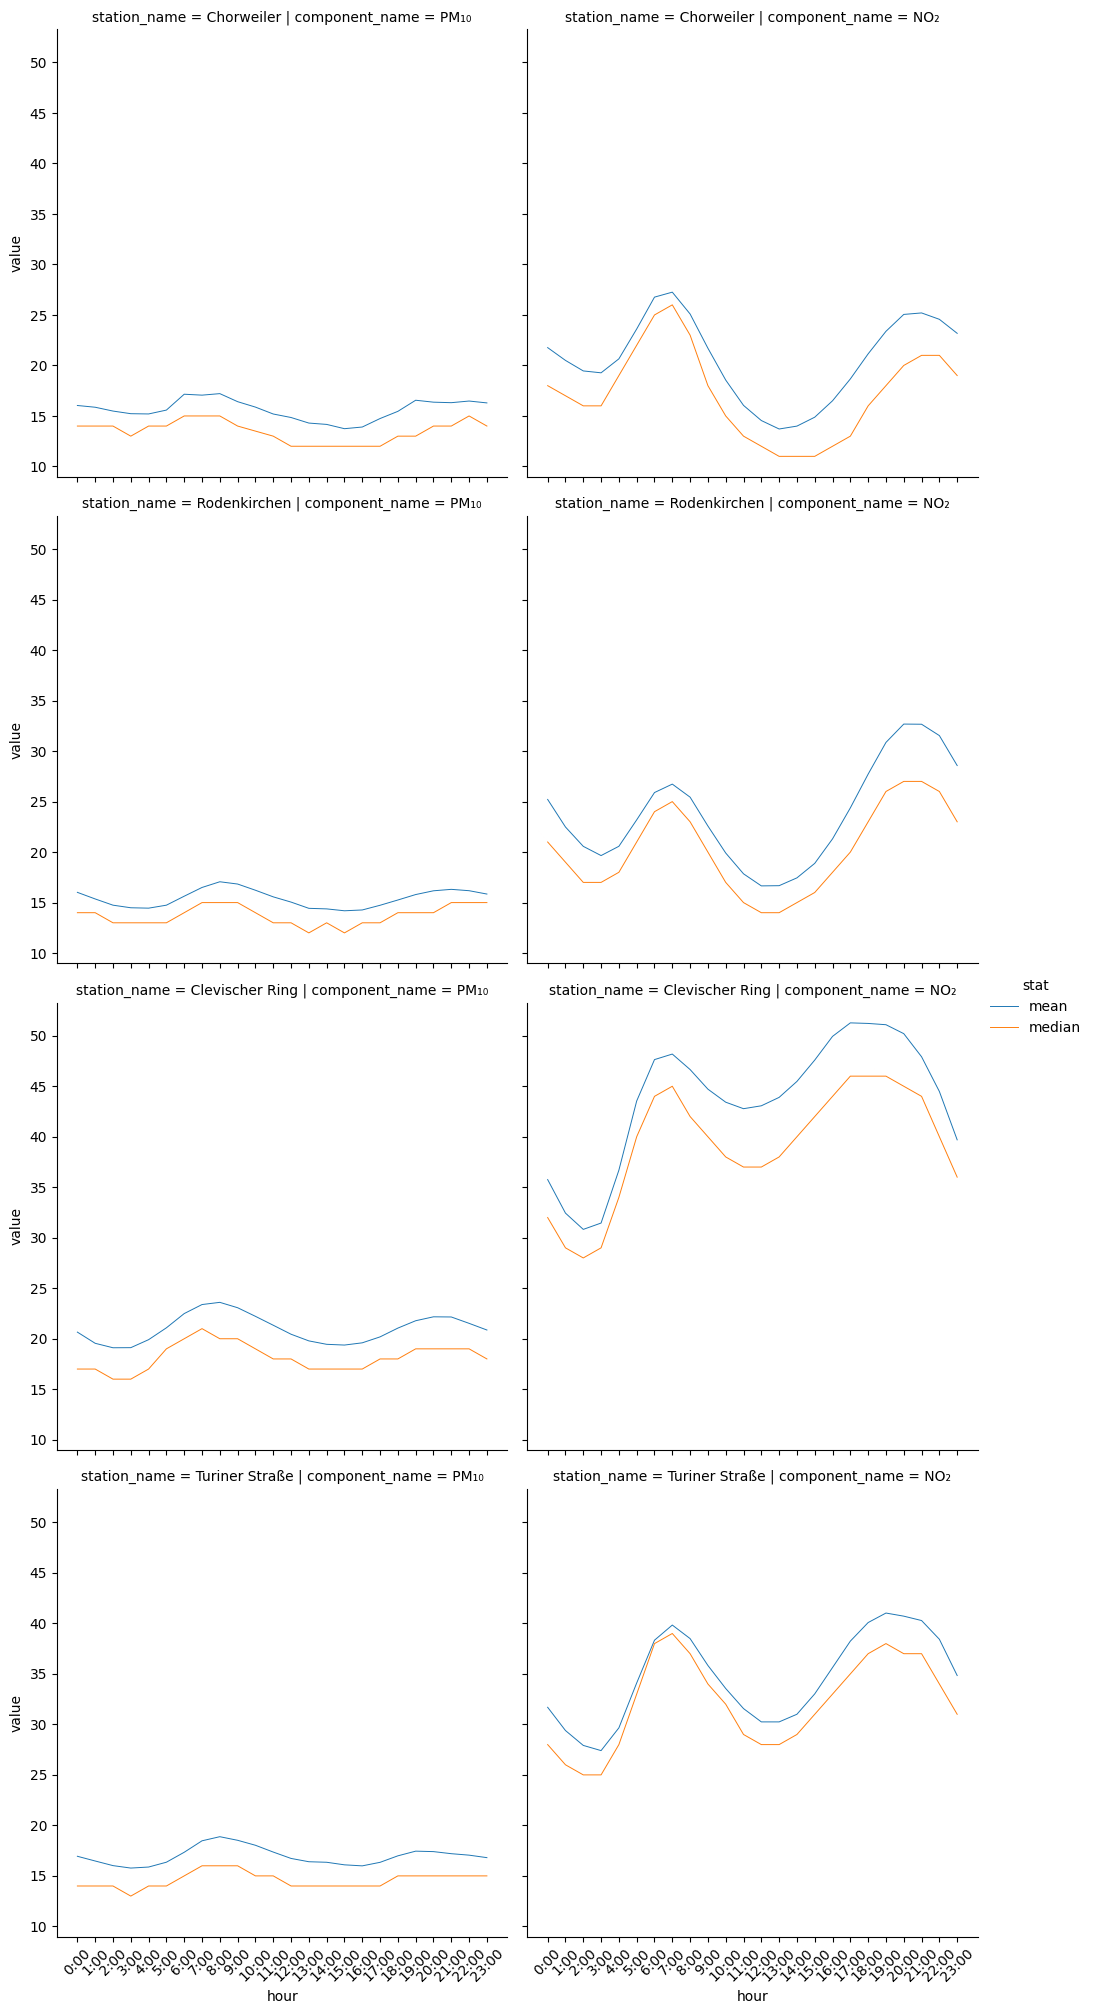

In [ ]:
hourly_mea_med = calc_curves(by="hour")

p = sns.relplot(
    data=hourly_mea_med,
    x="hour",
    y="value",
    kind="line",
    row="station_name",
    col="component_name",
    hue="stat",
    linewidth=0.7,
)
p.set(xticks=range(24))
p.set_xticklabels([f"{c}:00" for c in range(24)], rotation=45)

> mean reacts more to the outliers than the median (systematically over the median) \
> peak hours at 7:00 & 19:00 \
> NO₂: background stations have systematically smaller concentration values than traffic stations \
> PM₁₀: background and traffic stations are comparable

### average concentration per week

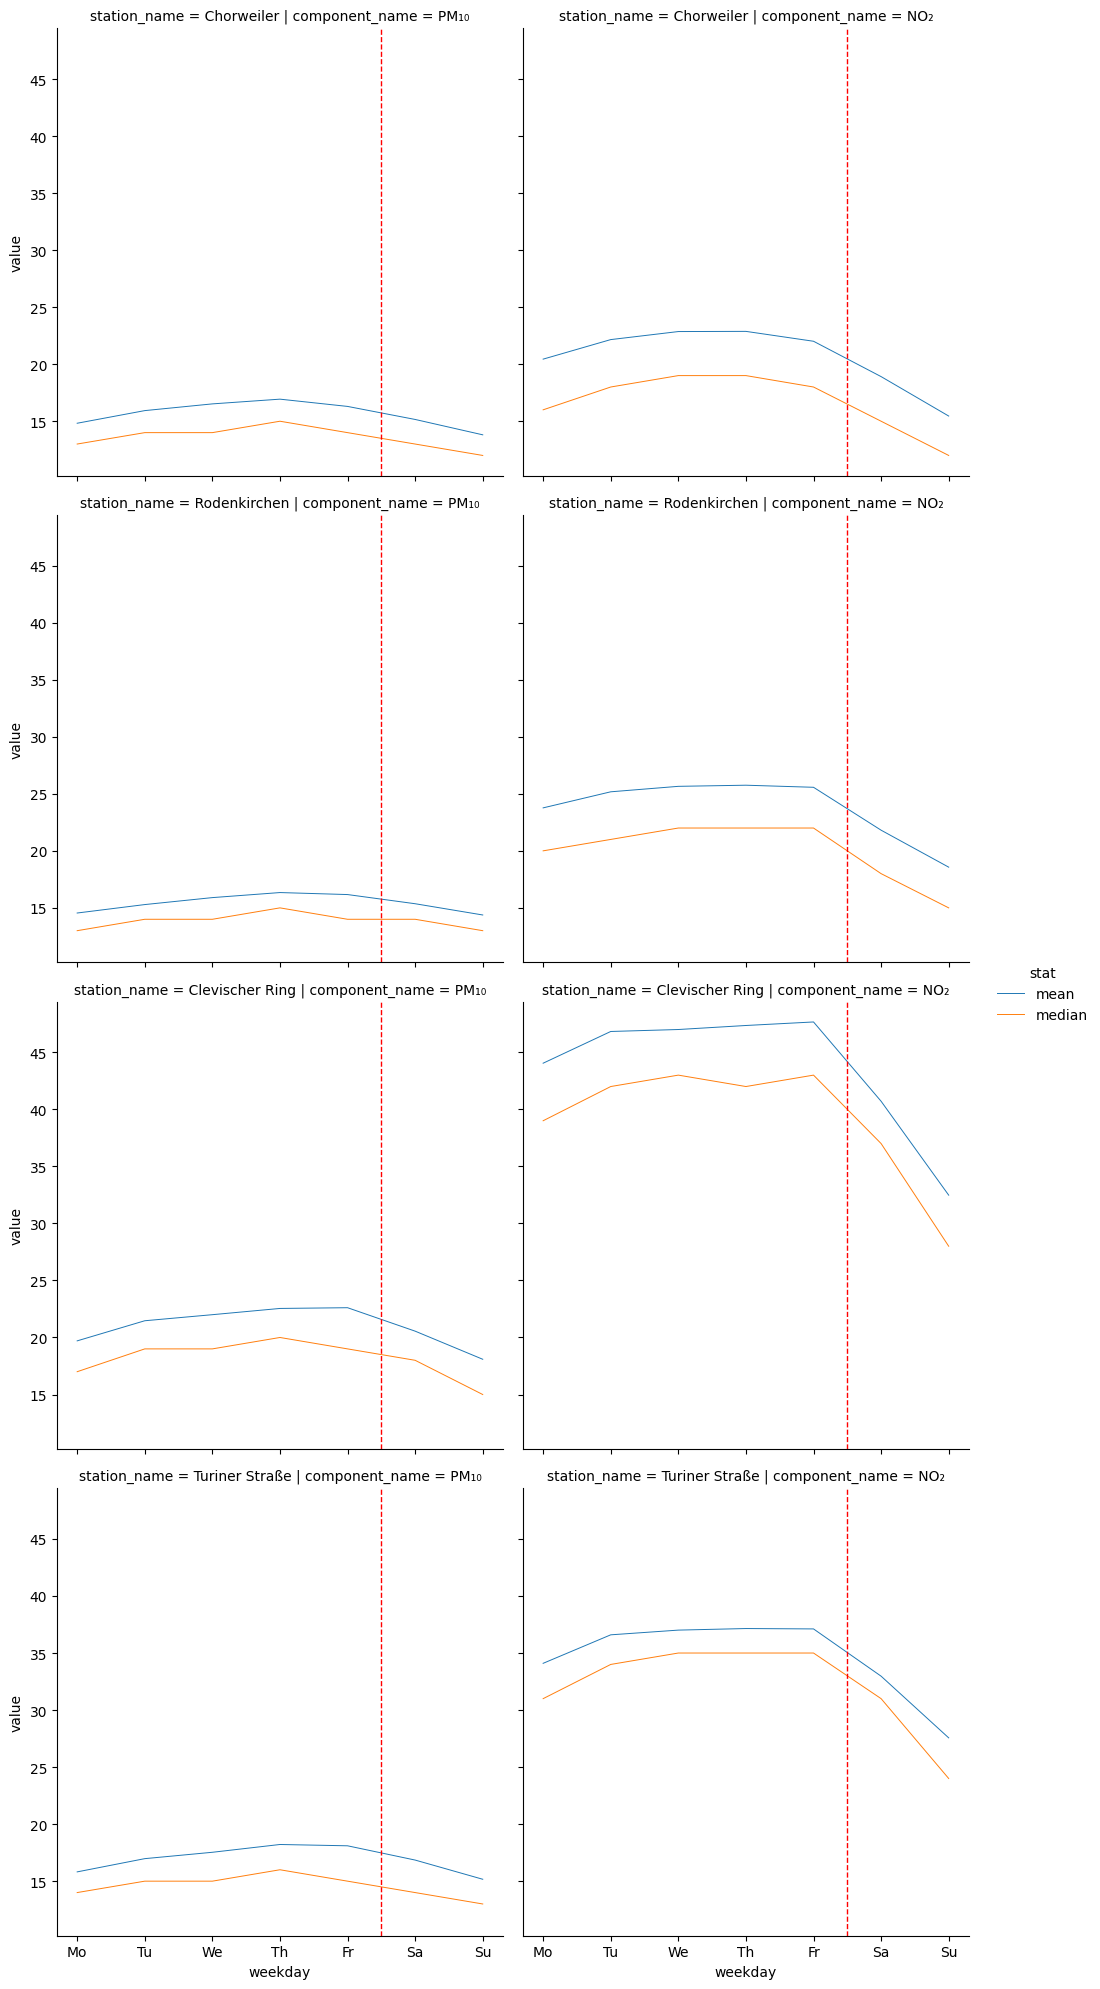

In [ ]:
weekly_mea_med = calc_curves(by="weekday")

p = sns.relplot(
    data=weekly_mea_med,
    x="weekday",
    y="value",
    kind="line",
    row="station_name",
    col="component_name",
    hue="stat",
    linewidth=0.7,
)
p.refline(x=4.5, color="red", linestyle="--", linewidth=1, label="weekend")
p.set(xticks=range(7), xticklabels=["Mo", "Tu", "We", "Th", "Fr", "Sa", "Su"])

> weekends tend to have smaller concentrations (especially traffic stations and NO₂)

### average concentration per month

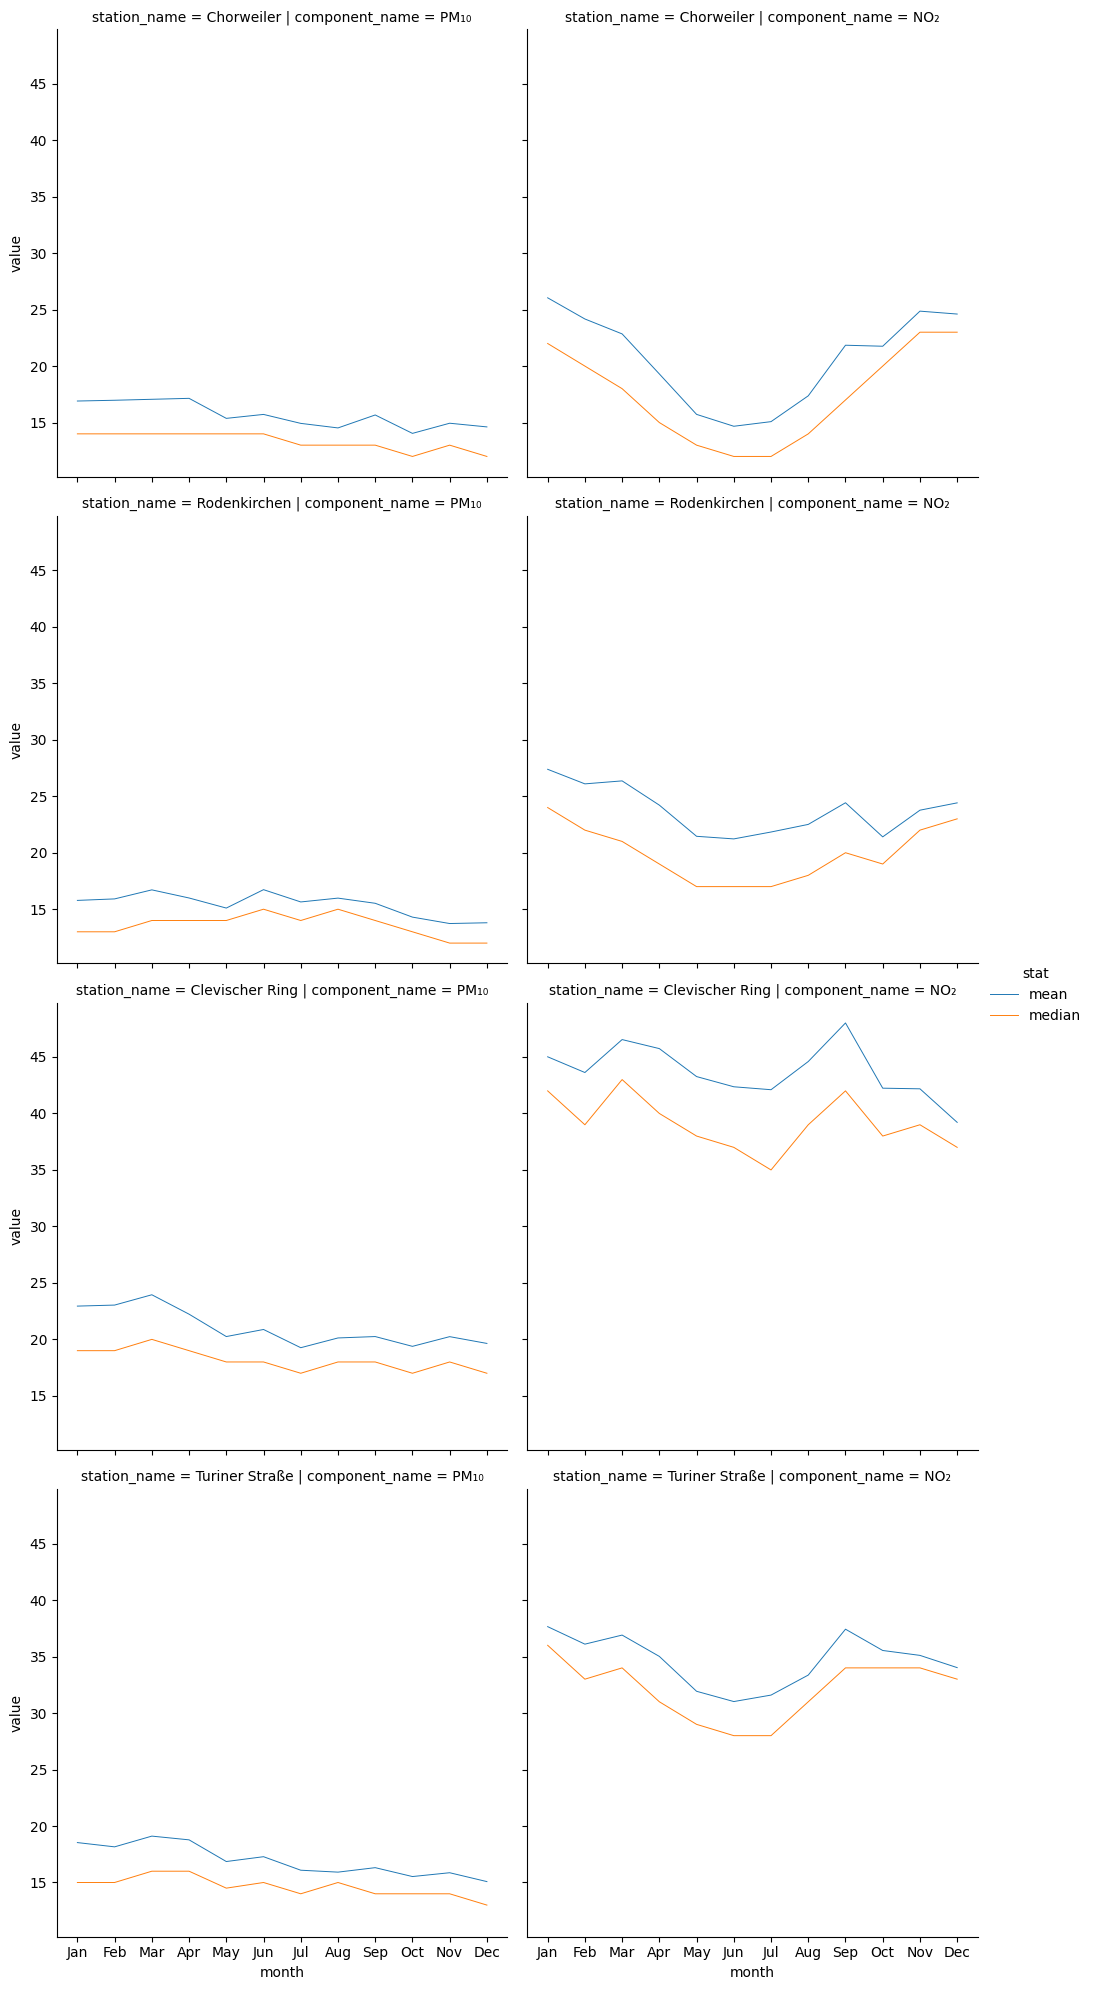

In [ ]:
monthly_mea_med = calc_curves(by="month")

p = sns.relplot(
    data=monthly_mea_med,
    x="month",
    y="value",
    kind="line",
    row="station_name",
    col="component_name",
    hue="stat",
    linewidth=0.7,
)
p.set(
    xticks=range(1, 13),
    xticklabels=[
        "Jan",
        "Feb",
        "Mar",
        "Apr",
        "May",
        "Jun",
        "Jul",
        "Aug",
        "Sep",
        "Oct",
        "Nov",
        "Dec",
    ],
)

> summer month tend to have less emissions (NO₂) \
> effect is more visible at background stations \
> PM₁₀ seems to be less influenced by monthly changes

### average concentration per year

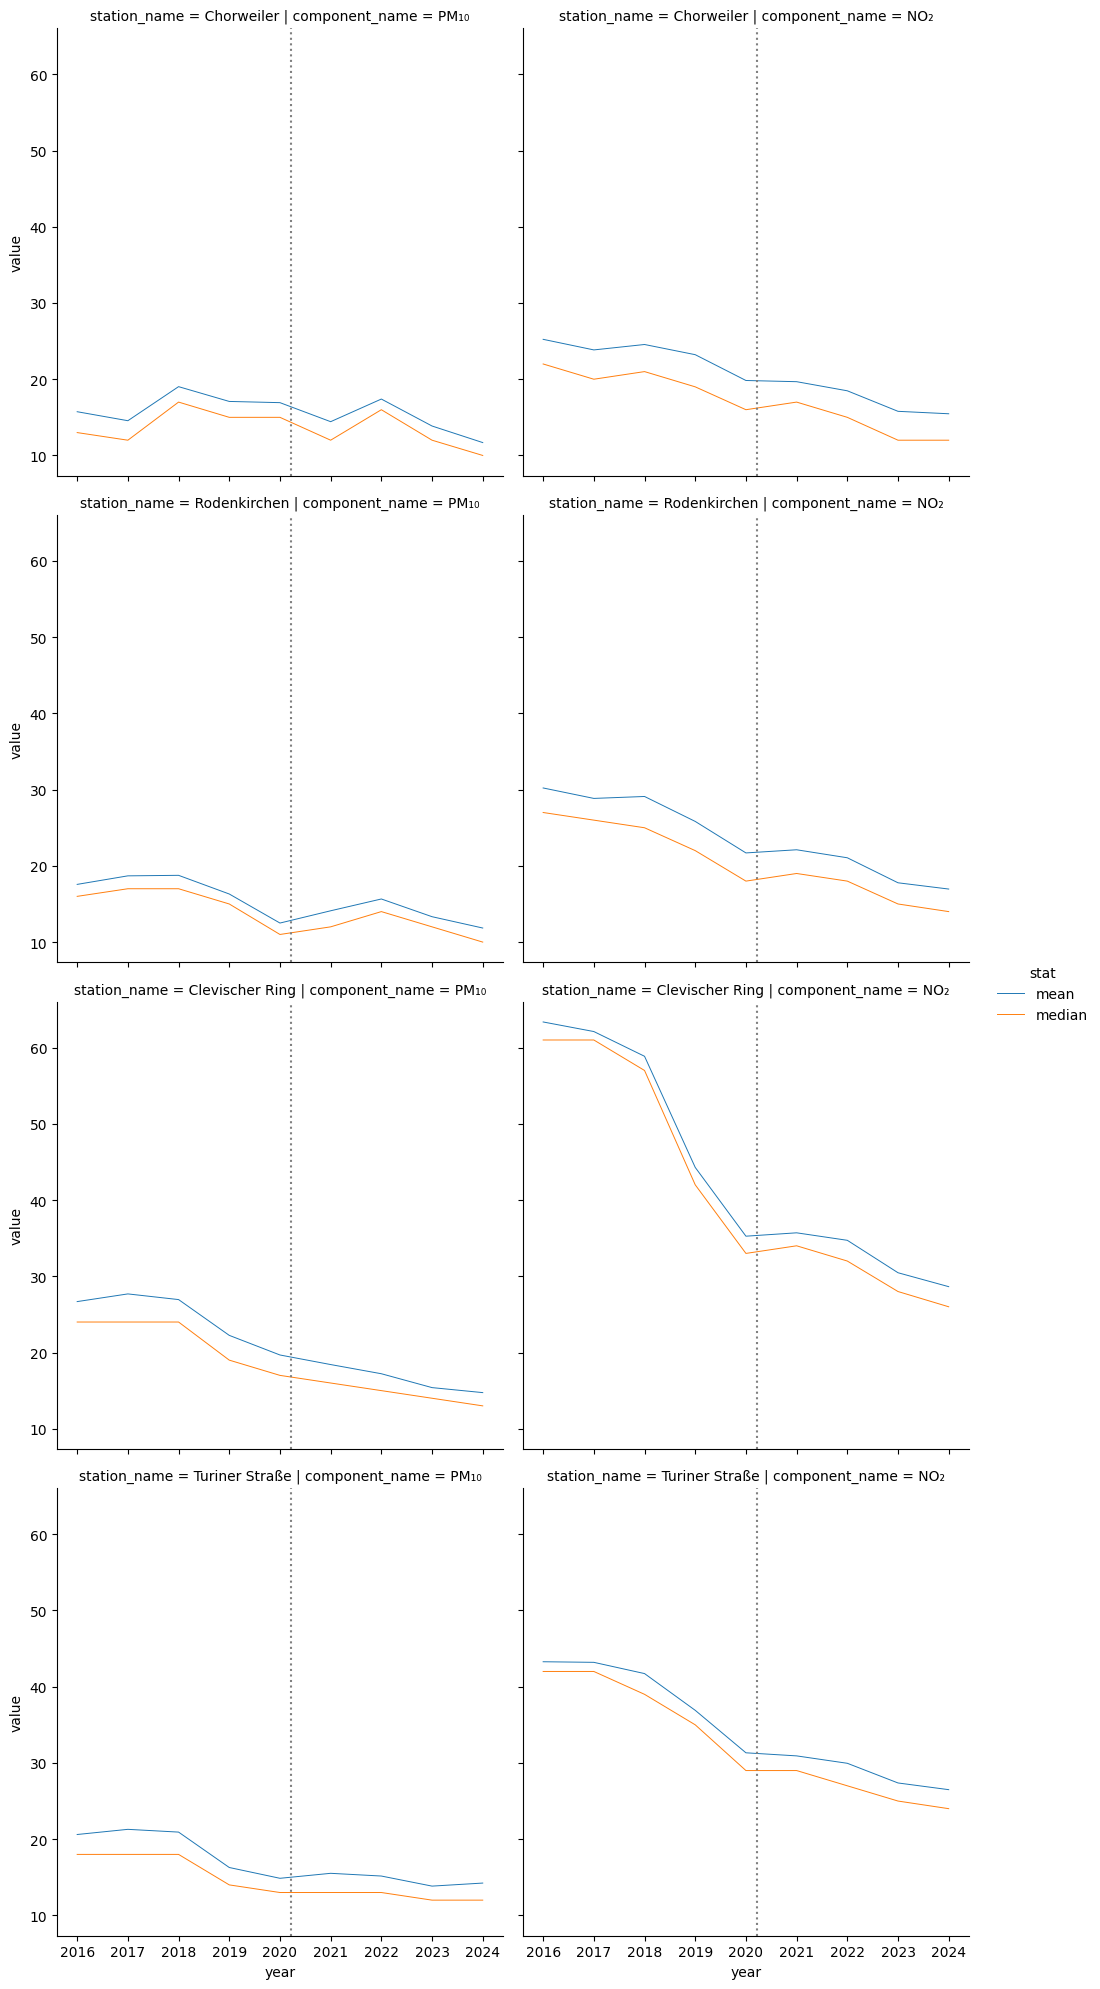

In [ ]:
yearly_mea_med = calc_curves(by="year")

p = sns.relplot(
    data=yearly_mea_med,
    x="year",
    y="value",
    kind="line",
    row="station_name",
    col="component_name",
    hue="stat",
    linewidth=0.7,
)
p.refline(
    x=2020 + 81 / 366, color="grey", linestyle=":", label="Lockdown"
)  # for 22/03/2020, start of the corona lockdown

> emission drop off from 2018 onwards (especially at traffic stations (and NO₂))

### new years eve concentration analysis

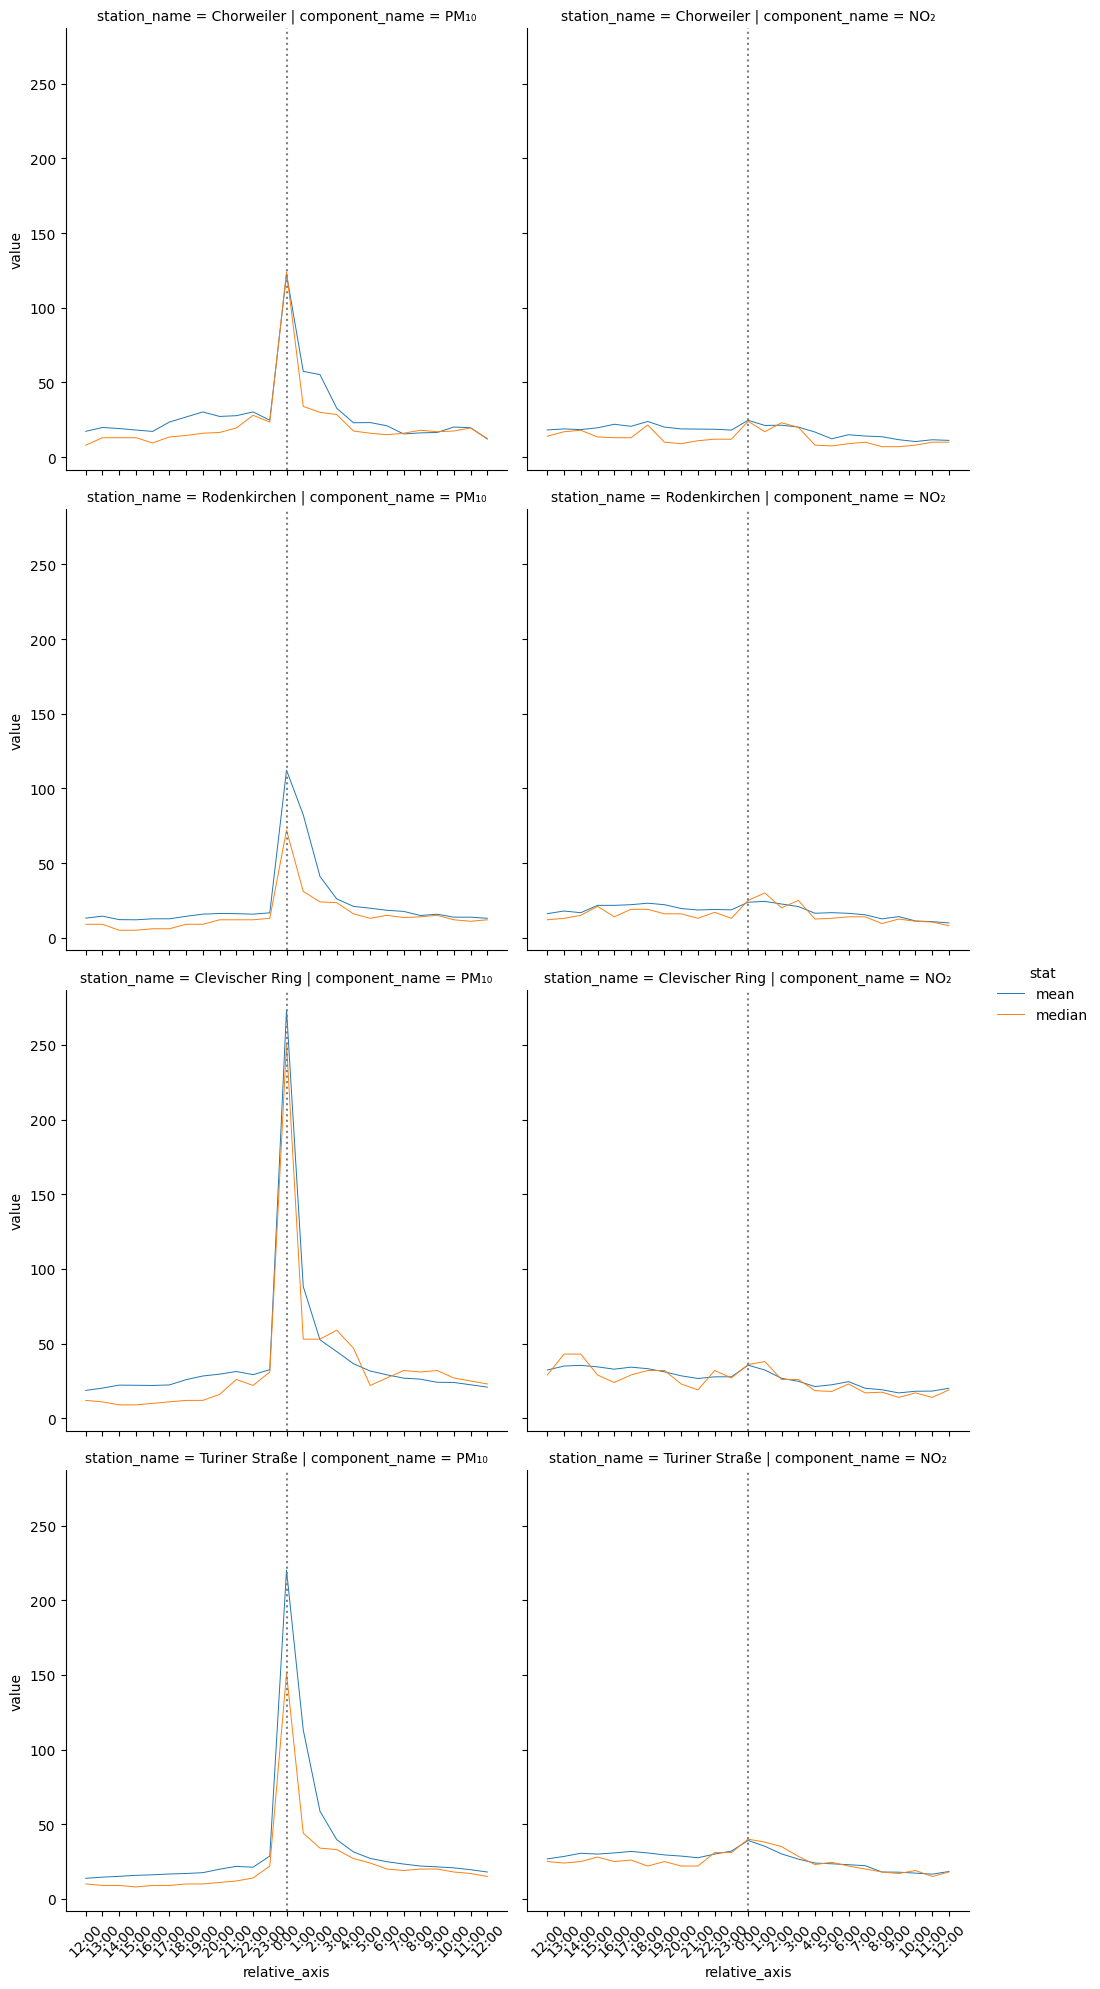

In [ ]:
d = df["date_start"].dt

new_years = df[
    ((d.month == 1) & (d.day == 1) & (d.hour.isin(range(13))))
    | ((d.month == 12) & (d.day == 31) & (d.hour.isin(range(12, 24))))
]

new_years = new_years.copy()
dn = new_years["date_start"].dt

new_years["relative_axis"] = np.where(dn.month == 1, dn.hour, dn.hour - 24)

new_yearly_mea_med = calc_curves(by="relative_axis", data=new_years)

p = sns.relplot(
    data=new_yearly_mea_med,
    x="relative_axis",
    y="value",
    kind="line",
    row="station_name",
    col="component_name",
    hue="stat",
    linewidth=0.7,
)
p.set(xticks=range(-12, 13))
p.set_xticklabels([f"{c % 24}:00" for c in range(-12, 13)], rotation=45)
p.refline(x=0, color="grey", linestyle=":", label="New Years")

> drastic peaks of PM₁₀-concentrations around new years eve \
> especially at traffic stations \
> NO₂ largely unaffected